# Gnasher Group — Version 2: trained seven-group classifier
**Irene Ramos · ITAI 1378 · Tier 1**

This is the next development stage, not a completed training report. No V2
accuracy, speed, confusion matrix, or trained weights have been recorded yet.
Version 1 is preserved under `prototypes/v1/` with its original saved outputs.

**What you will learn:** labeling, data splits, transfer learning, validation,
and paired testing. We train a new seven-output layer, then fine-tune the last
three feature blocks of pretrained EfficientNet-B0. The existing model is our
baseline, not discarded work.

Before running, choose **Runtime → Change runtime type → T4 GPU** in Colab.
Keep this notebook in your Google Drive. Training requires you to review the
breed table first. Run cells step by step rather than blindly running all.

## 1. Set up the repository and packages
The repository is public. No GitHub token is needed. The cell records the actual
source commit used so an experiment can be traced to its code.

In [12]:
%pip install -q torch torchvision pillow matplotlib pandas numpy
from pathlib import Path
import subprocess, sys, json

REPO = Path('/content/gnasher-final-source')
if not REPO.exists():
    subprocess.run(['git','clone','--depth','1',
                    'https://github.com/IreneAlexRamos/itai1378-project.git',str(REPO)], check=True)
SOURCE_COMMIT = subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip()
sys.path.insert(0,str(REPO / 'src'))
sys.path.insert(0,str(REPO))
print('Source commit:',SOURCE_COMMIT)

Source commit: 5402e9f2a5d7ad6ab1eccc5fe373f399417aaf49


## 2. Save artifacts in Drive and set the experiment
The source images live in the temporary Colab runtime for faster access.
Reviewed labels, splits, checkpoints, and reports go to Drive. Use a new
experiment name when changing labels, settings, or training again. A disconnected
run keeps its `best.pt`, `last.pt`, and history; these can be loaded for inference.
The initial workflow does not resume an interrupted optimizer state.

In [16]:
from google.colab import drive
drive.mount('/content/drive')
import torch, torchvision
from gnasher_data import download_dataset, draft_label_table, read_reviewed_labels, build_manifest, GROUPS
from gnasher_training import make_loaders, train_model, load_best, select_threshold, evaluate_paired, benchmark_model, predict_photo
from gnasher_group_mapping import BREED_TO_GROUP, UNSUPPORTED_DOG_LABELS, aggregate_group_scores

PROJECT = Path('/content/drive/MyDrive/GnasherGroup')
EXPERIMENT_NAME = 'v2_run04' # Change for a genuinely new experiment.
EXPERIMENT = PROJECT / 'experiments' / EXPERIMENT_NAME
EXPERIMENT.mkdir(parents=True,exist_ok=True)
REVIEW_TABLE = PROJECT / 'stanford_breed_to_group_review.csv'
DATA_ROOT = Path('/content/stanford_dogs')
SEED, CAP_PER_GROUP, BATCH_SIZE = 42, 1000, 32
HEAD_EPOCHS, FINE_EPOCHS = 3, 5
TRAIN_NOW = True  # Set False to load an existing best.pt without retraining.
print('GPU:',torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No GPU selected')
print('Artifacts:',EXPERIMENT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Artifacts: /content/drive/MyDrive/GnasherGroup/experiments/v2_run04


## 3. Get the original Stanford Dogs photographs
Source: http://vision.stanford.edu/aditya86/ImageNetDogs/

The original dataset has 20,580 images and 120 source breed folders. The download
may take time. If Stanford is unavailable, obtain `images.tar` from the official
page and upload it to `/content/stanford_dogs/`, then rerun this cell.

We use full photographs, not bounding-box crops. The model's validation/test
preprocessing resizes and center-crops them. **Stanford Dogs is ImageNet-derived**;
test separation below is from this project's fine-tuning, not proof of separation
from ImageNet pretraining.

In [4]:
import importlib
import gnasher_data

subprocess.run(
    ["git", "-C", str(REPO), "pull", "--ff-only"],
    check=True
)
SOURCE_COMMIT = subprocess.check_output(
    ["git", "-C", str(REPO), "rev-parse", "HEAD"],
    text=True
).strip()

importlib.reload(gnasher_data)
IMAGES = gnasher_data.download_dataset(DATA_ROOT)

Free disk space: 70.2 GiB
Download attempt failed: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Hostname mismatch, certificate is not valid for 'vision.stanford.edu'. (_ssl.c:1032)>
Downloaded 64 MiB
Downloaded 128 MiB
Downloaded 192 MiB
Downloaded 256 MiB
Downloaded 320 MiB
Downloaded 384 MiB
Downloaded 448 MiB
Downloaded 512 MiB
Downloaded 576 MiB
Downloaded 640 MiB
Downloaded 704 MiB
Download complete.
Extracting photographs...
Extracted 1,000 photographs
Extracted 2,000 photographs
Extracted 3,000 photographs
Extracted 4,000 photographs
Extracted 5,000 photographs
Extracted 6,000 photographs
Extracted 7,000 photographs
Extracted 8,000 photographs
Extracted 9,000 photographs
Extracted 10,000 photographs
Extracted 11,000 photographs
Extracted 12,000 photographs
Extracted 13,000 photographs
Extracted 14,000 photographs
Extracted 15,000 photographs
Extracted 16,000 photographs
Extracted 17,000 photographs
Extracted 18,000 photographs
Extracted 19,000 photo

## 4. Make It Yours — review the actual breed labels
This is real labeling work. The helper inventories the downloaded dataset's
exact folder identifiers and suggests labels from V1; it does **not** certify them.

1. Open the CSV in a spreadsheet. Review each canonical breed and AKC group using
   an official AKC breed page; correct aliases, varieties, and source URLs.
2. Keep unresolved labels excluded (`include=no`) and explain why in `notes`.
   Do not assume “Eskimo dog” means American Eskimo Dog. Wild-canid or unsupported
   categories also need documented exclusions rather than a forced group.
3. After actually checking each row, set `review_status=reviewed` and
   `reviewed_by=Irene Ramos`. Keep all source identifiers and all columns.
4. Export the reviewed spreadsheet as CSV and upload it in the next cell.

Do not mark rows reviewed just to bypass the check. This work should appear in
your reflection and AI usage log. A cap of 1,000 per group is a maximum;
exclusions or availability can make the total less than 7,000.

In [5]:
import pandas as pd
draft_label_table(IMAGES,BREED_TO_GROUP,UNSUPPORTED_DOG_LABELS,REVIEW_TABLE)
labels = pd.read_csv(REVIEW_TABLE,keep_default_na=False)
display(labels)
print('CSV to review:',REVIEW_TABLE)
# Optional download for editing in a spreadsheet:
# from google.colab import files
# files.download(str(REVIEW_TABLE))

,stanford_breed_id,source_breed_name,canonical_breed,akc_group,include,source_url,notes,review_status,reviewed_by
0,n02085620-Chihuahua,Chihuahua,Chihuahua,Toy,yes,https://www.akc.org/dog-breeds/toy/,Suggested from V1; verify breed and AKC group.,reviewed,Irene Ramos
1,n02085782-Japanese_spaniel,Japanese_spaniel,Japanese Chin,Toy,no,https://www.akc.org/dog-breeds/toy/,Excluded programmatically due to duplicate ima...,reviewed,Irene Ramos
2,n02085936-Maltese_dog,Maltese_dog,Maltese dog,Toy,yes,https://www.akc.org/dog-breeds/toy/,Suggested from V1; verify breed and AKC group.,reviewed,Irene Ramos
3,n02086079-Pekinese,Pekinese,Pekinese,Toy,yes,https://www.akc.org/dog-breeds/toy/,Suggested from V1; verify breed and AKC group.,reviewed,Irene Ramos
4,n02086240-Shih-Tzu,Shih-Tzu,Shih-Tzu,Toy,no,https://www.akc.org/dog-breeds/toy/,Excluded programmatically due to duplicate ima...,reviewed,Irene Ramos
...,...,...,...,...,...,...,...,...,...
115,n02113799-standard_poodle,standard_poodle,standard poodle,Non-Sporting,yes,https://www.akc.org/dog-breeds/non-sporting/,Suggested from V1; verify breed and AKC group.,reviewed,Irene Ramos
116,n02113978-Mexican_hairless,Mexican_hairless,Xoloitzcuintli,Non-Sporting,yes,https://www.akc.org/dog-breeds/non-sporting/,Suggested from V1; verify breed and AKC group.,reviewed,Irene Ramos
117,n02115641-dingo,dingo,dingo,,no,http://vision.stanford.edu/aditya86/ImageNetDogs/,No verified V1 match; exclude until reviewed.,reviewed,Irene Ramos
118,n02115913-dhole,dhole,dhole,,no,http://vision.stanford.edu/aditya86/ImageNetDogs/,No verified V1 match; exclude until reviewed.,reviewed,Irene Ramos


CSV to review: /content/drive/MyDrive/GnasherGroup/stanford_breed_to_group_review.csv


In [6]:
IMPORT_REVIEWED_CSV = False  # Set True when your reviewed CSV is ready to upload.
if IMPORT_REVIEWED_CSV:
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith('.csv')]
    if len(csv_files) != 1:
        raise ValueError('Upload exactly one reviewed breed-table CSV.')
    # Validate the upload before replacing the persisted table.
    candidate = PROJECT / 'candidate_review.csv'
    candidate.write_bytes(uploaded[csv_files[0]])
    read_reviewed_labels(candidate,IMAGES)
    candidate.replace(REVIEW_TABLE)
reviewed = read_reviewed_labels(REVIEW_TABLE,IMAGES)
print('Reviewed rows:',len(reviewed))

Reviewed rows: 120


## 5. Create a fixed 70/15/15 split
The manifest labels every selected photograph with its source breed, group,
split, and SHA-256. Exact-byte duplicates are removed before sampling. A
conflicting duplicate label stops the workflow. Near duplicates remain a
limitation. The custom split follows the proposal; it differs from the dataset's
official 12,000/8,580 split and is not comparable to that benchmark directly.

Only training gets random image augmentation. Validation and test use the
pretrained model's deterministic transforms. The test set is not used for
training, model selection, or threshold selection.

In [17]:
manifest = build_manifest(IMAGES,REVIEW_TABLE,EXPERIMENT,cap=CAP_PER_GROUP,seed=SEED)
metadata = json.loads((EXPERIMENT/'manifest_metadata.json').read_text())
display(pd.DataFrame(manifest).groupby(['group','split']).size().unstack(fill_value=0).reindex(GROUPS))
print('Selected photographs:',len(manifest))
run_config = {'source_commit':SOURCE_COMMIT,'seed':SEED,'cap_per_group':CAP_PER_GROUP,
              'batch_size':BATCH_SIZE,'head_epochs':HEAD_EPOCHS,'fine_epochs':FINE_EPOCHS,
              'torch':str(torch.__version__),'torchvision':str(torchvision.__version__),
              'manifest_sha256':metadata['manifest_sha256']}
config_path = EXPERIMENT/'run_config.json'
if config_path.exists() and json.loads(config_path.read_text()) != run_config:
    raise ValueError('Experiment configuration changed. Use a new experiment name.')
config_path.write_text(json.dumps(run_config,indent=2))
loaders = make_loaders(IMAGES,manifest,batch_size=BATCH_SIZE,seed=SEED)

split,test,train,validation
group,,,
Sporting,150,700,150
Hound,150,700,150
Working,150,700,150
Terrier,150,700,150
Toy,150,700,150
Non-Sporting,150,700,150
Herding,150,700,150


Selected photographs: 7000


## 6. Train the seven-output head, then fine-tune
V1 summed outputs from a pretrained 1,000-label model. V2 replaces the final
layer with seven outputs and learns from the reviewed group labels.

First the feature extractor is frozen while the new head trains. Then the last
three feature blocks are unfrozen with a smaller learning rate. Frozen layers'
BatchNorm statistics remain fixed. Class weights come from **training counts**.
Validation chooses the best checkpoint and early stopping; test is untouched.
Default epochs are a starting experiment, not a promise of 85% accuracy.

In [18]:
if TRAIN_NOW:
    if not torch.cuda.is_available():
        raise RuntimeError('Select a Colab GPU before starting the full training run.')
    model, device = train_model(loaders,EXPERIMENT,metadata,seed=SEED,
                               head_epochs=HEAD_EPOCHS,fine_epochs=FINE_EPOCHS)
else:
    model, device, checkpoint = load_best(EXPERIMENT)
print('Checkpoint:',EXPERIMENT/'best.pt')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 85.5MB/s]


head 1/3: train 77.7%, validation 88.2%, 45s
head 2/3: train 89.7%, validation 90.1%, 40s
head 3/3: train 91.7%, validation 91.0%, 40s
fine_tune 1/5: train 79.0%, validation 89.0%, 44s
fine_tune 2/5: train 88.9%, validation 89.9%, 43s
fine_tune 3/5: train 92.1%, validation 90.3%, 43s
fine_tune 4/5: train 95.0%, validation 90.4%, 44s
fine_tune 5/5: train 96.4%, validation 91.1%, 44s
Checkpoint: /content/drive/MyDrive/GnasherGroup/experiments/v2_run04/best.pt


## 7. Inspect training and validation curves
Look for learning, unstable training, and a widening train/validation gap.
Describe the actual curves in your own words. Do not open test results to decide
which epoch or settings to keep.

,stage,epoch,learning_rate,train_loss,train_accuracy,validation_loss,validation_accuracy,epoch_seconds
0,head,1,0.0010,0.819895,0.776531,0.446420,0.881905,45.154059
1,head,2,0.0010,0.382505,0.896735,0.326751,0.900952,39.592570
2,head,3,0.0010,0.296154,0.916939,0.280389,0.909524,40.440279
3,fine_tune,1,0.0001,0.611655,0.790204,0.359320,0.889524,43.629877
4,fine_tune,2,0.0001,0.334314,0.889184,0.294010,0.899048,43.123251
5,fine_tune,3,0.0001,0.246572,0.920612,0.292662,0.902857,42.938421
6,fine_tune,4,0.0001,0.175253,0.949796,0.283749,0.903810,43.514098
7,fine_tune,5,0.0001,0.129784,0.963673,0.273113,0.911429,44.132280


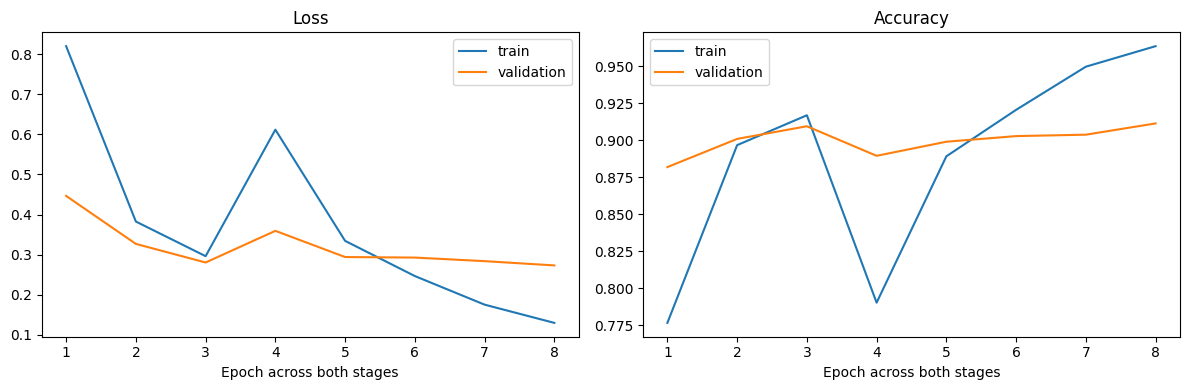

In [19]:
import matplotlib.pyplot as plt
history = pd.read_csv(EXPERIMENT/'history.csv')
display(history)
fig,axes = plt.subplots(1,2,figsize=(12,4))
x = range(1,len(history)+1)
for split in ['train','validation']:
    axes[0].plot(x,history[f'{split}_loss'],label=split)
    axes[1].plot(x,history[f'{split}_accuracy'],label=split)
axes[0].set_title('Loss'); axes[1].set_title('Accuracy')
for ax in axes:
    ax.set_xlabel('Epoch across both stages'); ax.legend()
fig.tight_layout(); fig.savefig(EXPERIMENT/'learning_curves.png',dpi=160); plt.show()

## 8. Lock the confidence threshold using validation
The provisional rule tries thresholds from 0.50 through 0.95. It picks the
smallest with at least 80% validation coverage and 85% accepted accuracy, falling
back to 0.50 when none qualify. This is a declared experiment rule, not
calibration or proof of non-dog detection. We will report full top-1 accuracy,
coverage, accepted accuracy, and abstentions separately.

In [20]:
selection = select_threshold(model,loaders['validation'],device,EXPERIMENT)
display(pd.DataFrame(selection['candidates']))
print('Locked threshold:',selection['threshold'])
print('Validation coverage/accuracy criterion met:',selection['criterion_met'])

,threshold,coverage,accepted_accuracy
0,0.50,0.971429,0.929412
1,0.55,0.957143,0.933333
2,0.60,0.936190,0.938962
3,0.65,0.909524,0.946597
4,0.70,0.890476,0.951872
5,0.75,0.863810,0.959206
6,0.80,0.840000,0.965986
7,0.85,0.816190,0.971995
8,0.90,0.771429,0.974074
9,0.95,0.689524,0.977901


Locked threshold: 0.5
Validation coverage/accuracy criterion met: True


## 9. Evaluate once on the held-out test photographs
Compare **both versions on exactly the same images**. V1 keeps its 50% rule; V2
uses its validation-selected threshold. The old eight-photo demonstration rate
is not a fair comparison with this larger test split.

The primary classifier result is full top-1 test accuracy. The decision accuracy
keeps abstentions in the denominator. Accepted accuracy is a separate metric.
Do not change settings based on these test results and reuse the same test set
to claim an unbiased final improvement. Future retuning needs a new independent
evaluation or an explicitly disclosed exploratory analysis.

In [21]:
report = evaluate_paired(model,loaders['test'],device,EXPERIMENT,aggregate_group_scores)
display(pd.DataFrame({name:{key:value for key,value in report[name].items()
                           if key not in ['confusion_matrix','decision_matrix_with_uncertain','per_group_accuracy']}
                      for name in ['prototype_v1','trained_v2']}))
print(report['limitations'])

,prototype_v1,trained_v2
n,1050.000000,1050.000000
top1_accuracy,0.971429,0.901905
coverage,0.960000,0.978095
abstentions,42.000000,23.000000
accepted_accuracy,0.983135,0.914314
correct_with_abstentions_counted_in_denominator,0.943810,0.894286


Held out from project fine-tuning only; ImageNet pretraining overlap and near duplicates are possible. No reliable non-dog detection established.


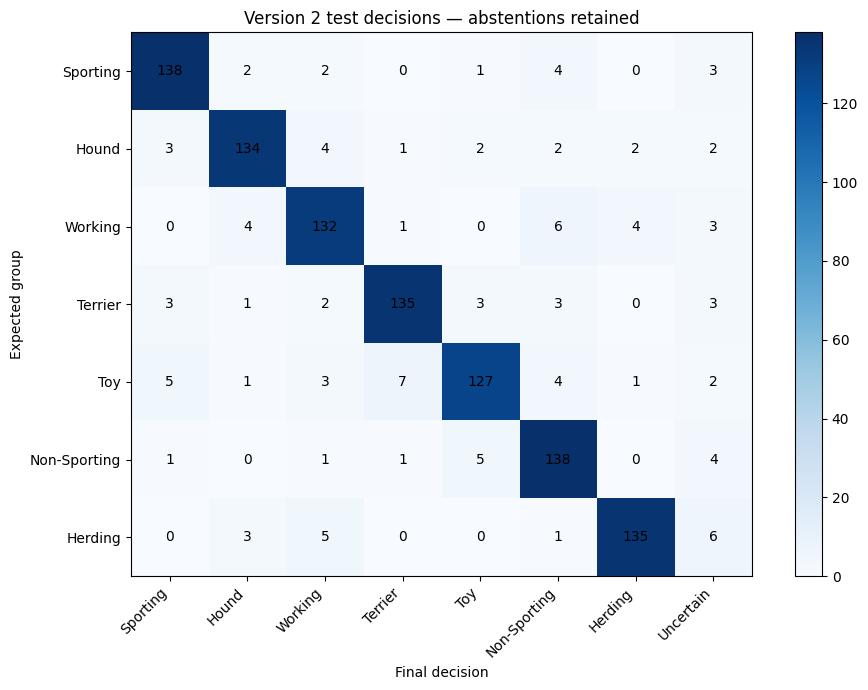

In [22]:
import numpy as np
matrix = np.array(report['trained_v2']['decision_matrix_with_uncertain'])
fig,ax = plt.subplots(figsize=(10,7))
im=ax.imshow(matrix,cmap='Blues')
ax.set_xticks(range(8),GROUPS+['Uncertain'],rotation=45,ha='right')
ax.set_yticks(range(7),GROUPS)
ax.set_xlabel('Final decision'); ax.set_ylabel('Expected group')
ax.set_title('Version 2 test decisions — abstentions retained')
for i in range(7):
    for j in range(8):
        ax.text(j,i,str(matrix[i,j]),ha='center',va='center')
fig.colorbar(im,ax=ax); fig.tight_layout()
fig.savefig(EXPERIMENT/'confusion_with_uncertain.png',dpi=160); plt.show()

## 10. Inspect 3–5 actual errors
Use the predicted file paths and scores, not made-up screenshots. Include
abstentions when discussing decision failures. If fewer than five errors exist,
report the actual number. This inspection is explanation after evaluation,
not permission to retune against the test set.

,relative_path,expected_group,v2_top1,v2_top1_score,v2_decision
7,n02100583-vizsla/n02100583_11710.jpg,Sporting,Hound,0.594513,Hound
20,n02099712-Labrador_retriever/n02099712_4462.jpg,Sporting,Working,0.673200,Working
45,n02102318-cocker_spaniel/n02102318_11704.jpg,Sporting,Non-Sporting,0.493751,Uncertain
58,n02099429-curly-coated_retriever/n02099429_16.jpg,Sporting,Non-Sporting,0.919160,Non-Sporting
62,n02100583-vizsla/n02100583_1214.jpg,Sporting,Hound,0.598490,Hound


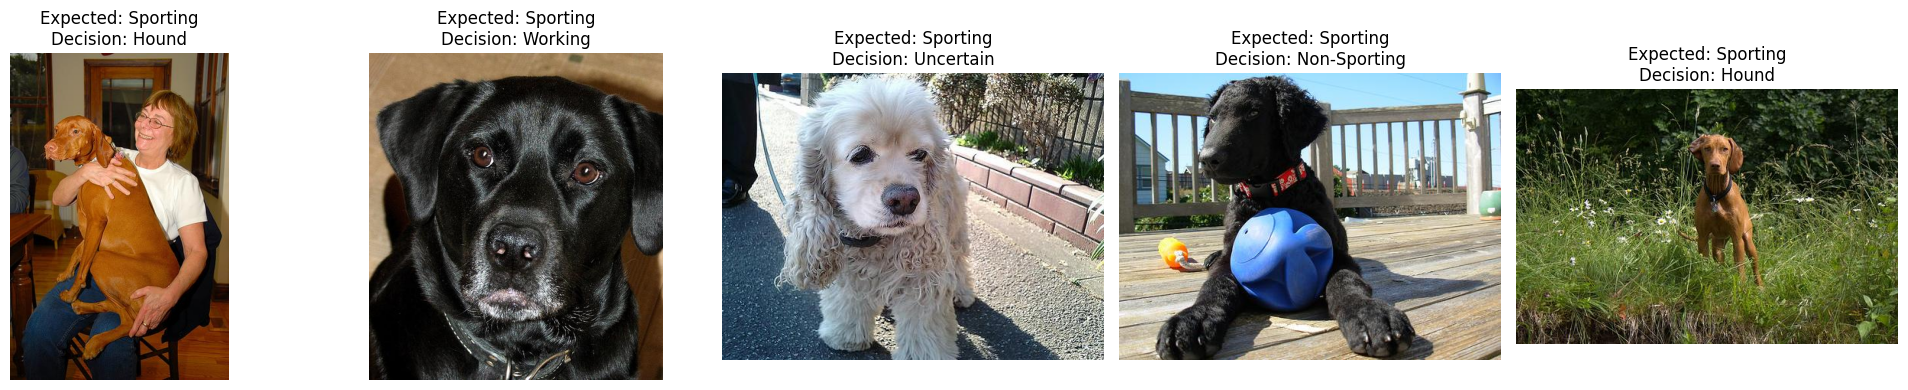

In [23]:
from PIL import Image
predictions = pd.read_csv(EXPERIMENT/'test_predictions.csv')
errors = predictions[predictions['v2_decision']!=predictions['expected_group']].head(5)
display(errors[['relative_path','expected_group','v2_top1','v2_top1_score','v2_decision']])
if len(errors):
    fig,axes=plt.subplots(1,len(errors),figsize=(4*len(errors),4),squeeze=False)
    for ax,(_,row) in zip(axes[0],errors.iterrows()):
        with Image.open(IMAGES/row['relative_path']) as photo:
            ax.imshow(photo.convert('RGB'))
        ax.set_title(f"Expected: {row['expected_group']}\nDecision: {row['v2_decision']}")
        ax.axis('off')
    fig.tight_layout(); fig.savefig(EXPERIMENT/'failure_examples.png',dpi=160); plt.show()
else:
    print('No decision errors in this run; report that outcome without inventing errors.')

## 11. Measure speed with the actual device
This reproduces V1's forward-only timing scope. It does not measure a whole
application response. Compare CPU to CPU or GPU to GPU; the historic V1 CPU
number is not an apples-to-apples comparison with a new GPU number.

In [24]:
speed = benchmark_model(model,IMAGES/loaders['test'].dataset.rows[0]['relative_path'],device)
(EXPERIMENT/'speed_report.json').write_text(json.dumps(speed,indent=2))
display(pd.DataFrame([speed]))

,device,runs,warmups,mean_forward_seconds,median_forward_seconds,scope
0,cuda,30,5,0.008122,0.007805,"preloaded batch, model forward only; excludes ..."


## 12. Try your own photograph and explain the limits
Upload Poppy, the husky, or another photograph. These are demonstrations, not
extra rows added to the held-out test score. You may also inspect Goober, but a
seven-group classifier has no cat class and can be confidently wrong on cats.
A low-confidence rule alone is not a validated non-dog detector.

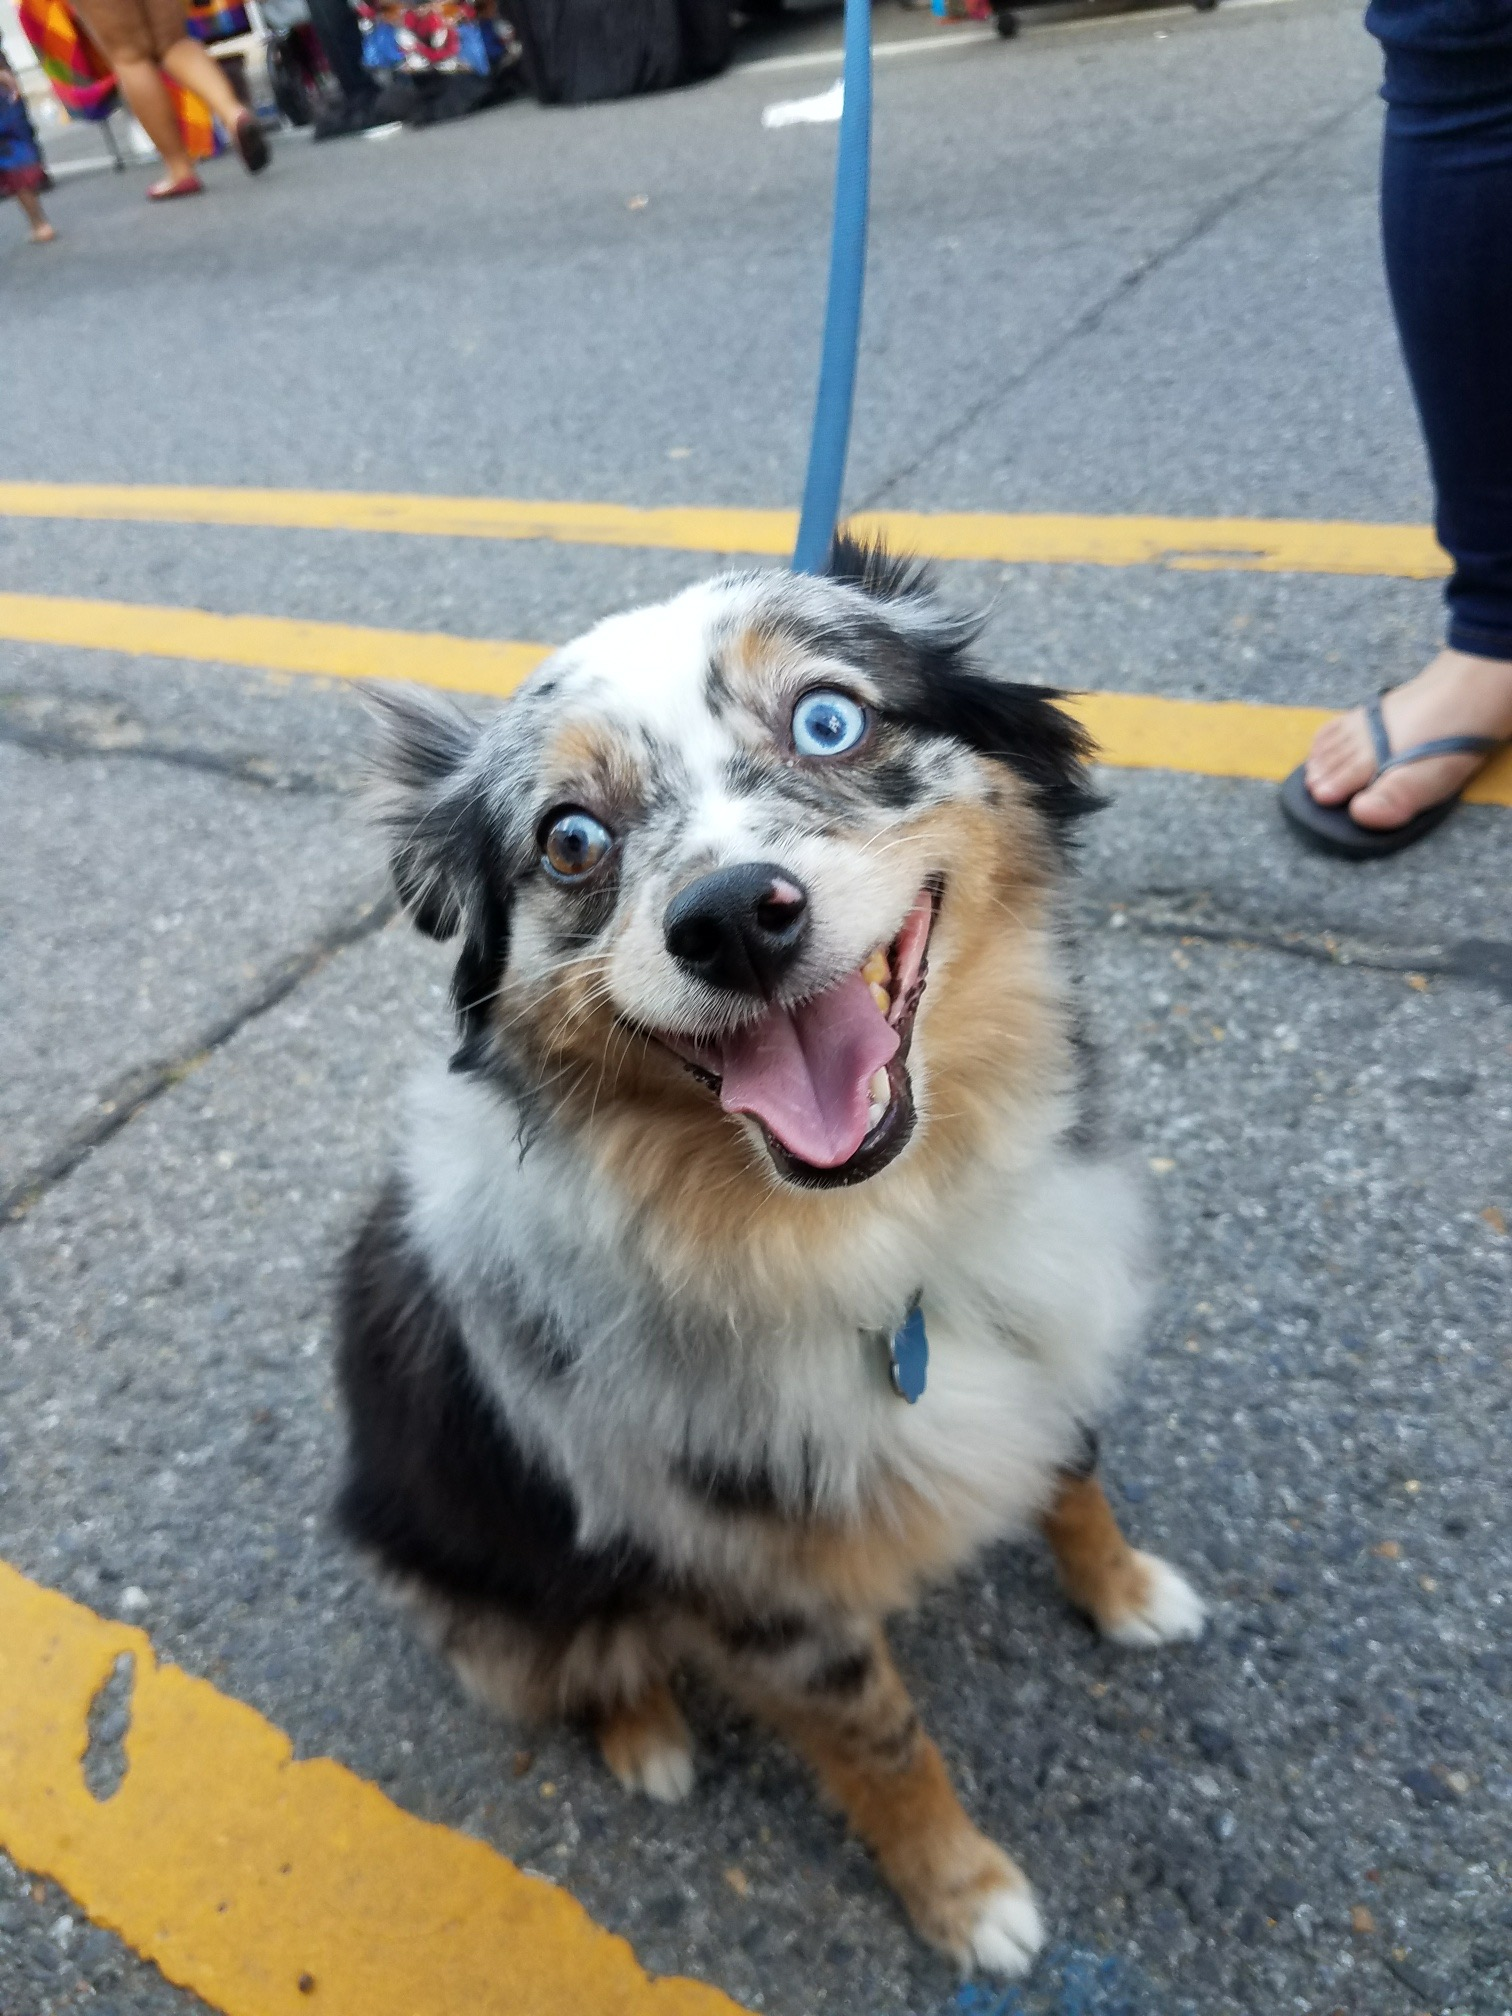

{
  "decision": "Herding",
  "top_two": [
    {
      "group": "Herding",
      "score": 0.8037469387054443
    },
    {
      "group": "Toy",
      "score": 0.16187946498394012
    }
  ],
  "note": "Seven-group closed-set model; this is not a non-dog detector."
}


In [25]:
DEMO_IMAGE = Path('/content/titus.JPG')  # Upload your photograph, then edit this path.
if DEMO_IMAGE.exists():
    decision = predict_photo(model,DEMO_IMAGE,device,selection['threshold'])
    display(Image.open(DEMO_IMAGE).convert('RGB'))
    print(json.dumps(decision,indent=2))
else:
    print('Optional demo: upload a photograph and edit DEMO_IMAGE, then rerun this cell.')

## 13. My reflection and submission evidence

### Which labels did I review?

I reviewed the breed-to-group table for the 120 Stanford Dogs source folders. The table connects the source breed names to the seven AKC groups and records exclusions.

Some names needed interpretation, such as “Boston bull” for Boston Terrier and “Japanese spaniel” for Japanese Chin. Unsupported or ambiguous labels and wild-canid categories remained excluded.

Some entire breed categories were also excluded after duplicate-label conflicts. This reduced breed coverage and is a limitation of my dataset preparation. A better future approach would investigate conflicting images individually instead of excluding a whole breed.

### How did head training and fine-tuning differ?

During the three head-training epochs, validation accuracy increased from 88.2% to 91.0%. This stage trained a new seven-output layer while keeping the pretrained feature extractor frozen.

During five fine-tuning epochs, I unfroze the last three feature blocks. Final training accuracy reached 96.4%, while validation accuracy reached 91.1%. Fine-tuning produced only a small validation improvement. The wider gap between training and validation suggests some overfitting.

### Did Version 2 improve on Version 1?

Both versions were evaluated on the same 1,050 test photographs.

| Measure | Version 1 prototype | Version 2 trained model |
|---|---:|---:|
| Top-1 accuracy | 97.14% | 90.19% |
| Correct final decisions, counting abstentions | 94.38% | 89.43% |
| Uncertain results | 42 | 23 |

Version 2 returned fewer uncertain results, but it made more incorrect predictions. Training did not improve performance on this test split.

This taught me that a more complex approach is not automatically better. My first version used pretrained breed predictions and group mapping. My second version helped me learn dataset labeling, transfer learning, validation, and controlled evaluation.

### What did my failure examples show?

The five displayed examples included two Vizslas predicted as Hound, a Labrador predicted as Working, a Cocker Spaniel that returned Uncertain, and a Curly-Coated Retriever predicted as Non-Sporting.

Similar appearances, camera angles, and backgrounds may contribute to these mistakes, but the examples alone do not establish their causes. The Curly-Coated Retriever received an incorrect leading score of approximately 91.9%, showing that a high score does not guarantee correctness.

The model has seven dog-group outputs and no cat class. It can return Uncertain, but that rule does not make it a reliable non-dog detector.

### How did the final build compare with my Blueprint?

I selected 7,000 photographs, with 1,000 per group. Each group contained 700 training, 150 validation, and 150 test images. The totals were:

- 4,900 training images
- 1,050 validation images
- 1,050 test images

Exact-byte duplicates were removed before sampling. Near duplicates may remain. This custom 70/15/15 split follows my proposal but differs from Stanford Dogs’ official split.

Version 2 reached 90.19% top-1 accuracy on this project’s held-out test split. However, Stanford Dogs is ImageNet-derived, so these images are not verified as unseen during the model’s original pretraining.

The trained model averaged approximately 0.0081 seconds per forward pass on a Tesla T4 GPU over 30 measured runs after five warm-ups. This excludes image loading, preprocessing, and total application response time.

### Personal demonstration

I tested the trained model on my photograph of Titus. It suggested Herding with an 80.4% score, followed by Toy at 16.2%. This was a separate demonstration and was not added to the test-set accuracy.

### Sources and AI assistance

Technical and labeling references included Stanford Dogs, the AKC breed directory, Torchvision’s EfficientNet-B0 documentation, and PyTorch’s transfer-learning tutorial.

ChatGPT/Codex helped prepare the notebooks, mapping, training workflow, debugging guidance, and documentation drafts. I reviewed the labeling table, ran the workflow in Colab, inspected the outputs, and supplied my photographs and personal reflections. ChatGPT also helped draft this reflection from my recorded results.

My completed run is saved under `v2_run04`. The first prototype remains preserved so the project shows both stages of development.